# II. YANN: Walidacja i rzetelna ocena modelu

Wytrenowanie sieci i obliczenie wartości funkcji straty na danych treningowych nie wystarcza, aby ocenić jakość modelu. Model może dobrze dopasować się do przykładów użytych podczas uczenia, a jednocześnie słabo działać na nowych obserwacjach. Na pomoc w tej sytuacji przychodzi proces ewaluacji.

Ewaluacja odpowiada na pytanie:

> Jakiej jakości predykcji możemy oczekiwać dla danych, których model nie widział podczas treningu?

W YANN proces ewaluacji obejmuje nie tylko obliczenie metryk. Odpowiada również za:

- podział danych na części treningowe i walidacyjne,
- przygotowanie danych bez przecieku informacji,
- utworzenie świeżego modelu dla każdego podziału,
- trening i generowanie predykcji,
- obliczenie metryk treningowych i walidacyjnych,
- obserwowanie przebiegu treningu w każdym splicie,
- agregację wyników z wielu splitów.

## Trening, walidacja i test

W typowym eksperymencie dane mogą pełnić trzy różne role:

| Część danych | Zastosowanie |
|---|---|
| treningowa | dopasowanie parametrów modelu |
| walidacyjna | ocena wariantu modelu i konfiguracji treningu |
| testowa | końcowa, niezależna ocena wybranego rozwiązania |

`ResamplingEvaluator` w YANN zajmuje się częścią treningową i walidacyjną. Nie zarządza osobnym zbiorem testowym. Jeżeli eksperyment wymaga końcowego testu, dane testowe należy odłożyć przed rozpoczęciem doboru modelu i nie wykorzystywać ich podczas walidacji.

Wynik walidacji jest efektem zrealizowania całego protokółu uczenia, który obejmuje: sposób podziału danych, preprocessing, architekturę sieci, funkcję straty, optymalizator i kryteria zatrzymania. Nie jest to zatem wyłącznie ocena jednej, konkretnej instancji sieci.

### Funkcja straty a metryka

Funkcja straty steruje uczeniem modelu i musi dostarczać gradient potrzebny do wykoania propagacji wstecznej. Z kolei, metryka służy do interpretacji jakości predykcji i nie musi już być różniczkowalna i może działać w jednostkach lepiej zrozumiałych dla użytkownika.

Przykładowo model regresyjny może uczyć się przez minimalizację `MSE`, a być oceniany za pomocą `MeanAbsoluteError` i `RootMeanSquaredError`. Model klasyfikacyjny może uczyć się z `SparseCategoricalCrossEntropy`, a być oceniany przez `Accuracy` i `SparseCategoricalCrossEntropy`.

Metryki treningowe pokazują dopasowanie do danych użytych podczas uczenia. Metryki walidacyjne pokazują jakość na danych niewidzianych podczas treningu. Warto mieć na uwadze, że duża różnica pomiędzy nimi może wskazywać na przeuczenie.

## Resampling i architektura ewaluacji

Pojedynczy podział train/validation może dać wynik zależny od tego, które obserwacje przypadkiem znalazły się w walidacji. Resampling powtarza trening dla kilku podziałów danych.

Do podziału danych dla resmplera YANN udostępnia:
- `HoldoutSplitter` - wykonuje jeden podział na train i validation. Domyślnie tasuje próbki, a `test_size` określa część danych przeznaczoną na walidację. Przydatny do szybkiej, jednorazowej oceny. Wynik zależy od tego konkretnego podziału,
- `KFoldSplitter` - dzieli próbki na `n_folds` części i wykonuje tyle podziałów. W każdym z nich inna część służy jako validation, a pozostałe jako train. Każda próbka trafia raz do walidacji. Przydatny dla niezależnych, wymiennych obserwacji, gdy chcesz ocenić model na kilku podziałach,
- `StratifiedKFoldSplitter` - działa jak K-fold, ale rozdziela próbki tak, by proporcje klas były zbliżone w każdym foldzie. Przydatny szczególnie w klasyfikacji z niezrównoważonymi klasami. Każda klasa musi mieć co najmniej tyle próbek, ile wynosi `n_folds`,
- `TimeSeriesSplitter` - tworzy kolejne podziały bez tasowania: train obejmuje wcześniejsze obserwacje, a validation - następujący po nich okres. Może rozszerzać zbiór treningowy w kolejnych splitach (`expanding=True`) albo przesuwać okno o stałym rozmiarze (`expanding=False`). Stosowany, gdy kolejność czasu ma znaczenie, na przykład przy prognozowaniu.

Dla każdego splitu ewaluator tworzy świeży model. Ponowne użycie wcześniej wytrenowanej sieci spowodowałoby przepływ informacji pomiędzy foldami i unieważniłoby wynik walidacji.

Dla każdego splitu ewaluacja przechodzi przez ten sam przepływ:

```text
Surowe dane: X (cechy) i Y (oczekiwane wyniki)
▼
├── 1. Podział danych
│   ├── Operacja
│   │   ├── Splitter (np. HoldoutSplitter, czy KFoldSplitter) wyznacza próbki train i validation zgodnie z wybraną strategią podziału
│   │   ├── TimeSeriesSplitter zachowuje chronologię - w każdym splicie train obejmuje wcześniejsze obserwacje, a validation późniejsze
│   └── Wynik: indeksy próbek dla obu zbiorów
▼
├── 2. Przygotowanie danych
│   ├── Specyfikacja
│   │   ├── ColumnSpec — wskazuje, które kolumny X i Y przetwarzać oraz jakie transformatory danych zastosować do każdej kolumny
│   │   └── WindowSpec — dla szeregów czasowych określa lookback, horizon i stride, czyli parametry tworzenia okien
│   ├── Operacja
│   │   ├── TabularSplitProcessor - korzysta z ColumnSpec, dopasowuje transformatory danych wyłącznie na train i stosuje je do train oraz validation.
│   │   └── TimeSeriesSplitProcessor - robi to samo, a następnie tworzy osobne okna train i validation zgodnie z WindowSpec
│   └── Wynik: PreparedSplit przechowuje przygotowane dane wejściowe i docelowe train oraz dane wejściowe validation i wartości
│       docelowe do scoringu, a także rozmiary wejścia i wyjścia po transformacjach oraz - dla szeregów czasowych - również po okienkowaniu
▼
├── 3. Utworzenie modelu
│   ├── Operacja: model_factory tworzy nową, niewytrenowaną instancję modelu na podstawie rozmiarów wejścia i wyjścia z PreparedSplit
│   └── Wynik: nowa, niewytrenowana instancja TrainableModel
▼
├── 4. Trening i predykcja
│   ├── Operacja: model uczy się na train, a następnie przewiduje wyniki dla train i validation
│   └── Wynik: predictions_for_scoring — predykcje przygotowane do oceny
▼
└── 5. Ocena
    ├── Operacja: obliczenie metryk i porównanie predykcje z oczekiwanym Y
    └── Wynik: EvaluationResult - metryki dla train i validation
```

## Preprocessing bez przecieku danych

Preprocessing jest częścią protokołu ewaluacji, a nie operacją wykonywaną jednorazowo przed podziałem danych.

Transformer danych może podczas `fit()` poznać średnią, odchylenie standardowe, zbiór kategorii, kolejność etykiet albo zakres wartości. Jeżeli zostanie dopasowany do całego zbioru przed walidacją, informacje z części walidacyjnej wpłyną na reprezentację danych treningowych - to jest **data leakage**:

```text
Surowe dane: X (cechy) i Y (oczekiwane wyniki)
▼
├── 1. Przygotowanie danych przed podziałem
│   ├── Operacja: SplitProcessor wywołuje fit() na całym zbiorze, który zawiera przyszłe próbki train i validation
│   └── Skutek: parametry transformacji uwzględniają również dane validation
▼
└── 2. Podział danych
    ├── Operacja: Splitter dzieli już przekształcone dane na train i validation
    └── Problem: validation wpłynęło na preprocessing, co może zafałszować ocenę

```

Poprawny przepływ dla każdego splitu:

```text
Surowe dane: X (cechy) i Y (oczekiwane wyniki)
▼
├── 1. Podział danych
│   ├── Operacja: Splitter wyznacza próbki train i validation
│   └── Wynik: indeksy próbek dla obu zbiorów
▼
└── 2. Przygotowanie danych
    ├── Operacja: SplitProcessor wyznacza parametry transformacji wyłącznie na train, a następnie stosuje je do train i validation
    └── Wynik: PreparedSplit — przygotowane X i Y obu zbiorów oraz rozmiary wejścia i wyjścia po transformacjach
```

Dla szeregów czasowych dochodzi chronologiczny podział i tworzenie okien:
```text
Surowe dane uporządkowane w czasie
▼
├── 1. Chronologiczny podział danych
│   ├── Operacja: TimeSeriesSplitter wyznacza wcześniejszy okres jako train, a późniejszy jako validation
│   └── Wynik: indeksy zachowujące kolejność czasową
▼
├── 2. Dopasowanie i zastosowanie transformacji
│   ├── Operacja: TimeSeriesSplitProcessor dopasowuje transformatory z ColumnSpec wyłącznie na train, a następnie stosuje je do train i validation
│   └── Wynik: przekształcone dane obu okresów
▼
└── 3. Tworzenie okien
    ├── Operacja: TimeSeriesSplitProcessor tworzy okna osobno w train i validation, zgodnie z lookback, horizon i stride z WindowSpec
    └── Wynik: próbki okienkowe w PreparedSplit - okno nie łączy obserwacji z train i validation
```

W YANN fabryka tworzy nowy processor dla każdego splitu. `TabularSplitProcessor` i `TimeSeriesSplitProcessor` dopasowują swoje transformatory na części treningowej danego splitu.

## Przygotowanie danych

`ColumnSpec` opisuje sposób przetwarzania jednej kolumny:

```python
ColumnSpec(
    index=0,
    transformers=[StandardScaler()],
    score_transformed=False,
)
```

Transformery danych z listy są wykonywane po kolei. Schemat wejścia i schemat celu są definiowane osobno, ponieważ cel może być transformowany na potrzeby treningu, ale oceniany w innej skali.

Dostępne transformacje obejmują między innymi `Passthrough`, `StandardScaler`, `OneHotEncoder`, `OrdinalEncoder`, `LabelEncoder`, `DateTimeFeatures` i `CyclicalEncoder`.

Po przygotowaniu splitu `PreparedSplit` zawiera:

- `X_train` - wejście modelu podczas treningu,
- `Y_train` - cel w przestrzeni używanej przez loss,
- `Y_train_for_scoring` - cel treningowy w przestrzeni metryk,
- `X_validation` - przygotowane wejście walidacyjne,
- `Y_validation_for_scoring` - cel walidacyjny dla metryk,
- `input_size` i `output_size` - rozmiary potrzebne fabryce modelu.

### Szczególne przypadki

#### Nieznane kategorie

`OneHotEncoder(handle_unknown="ignore")` pozwala przetworzyć kategorię, której nie było w części treningowej. Otrzyma ona zerowy wektor w kolumnach odpowiadających znanym kategoriom. Zapobiega to błędowi wykonania, ale ma konsekwencje semantyczne: model nie potrafi odróżnić różnych nieznanych kategorii.

#### Szeregi czasowe

W danych czasowych nie wolno losowo mieszać przeszłości z przyszłością. `TimeSeriesSplitter` zachowuje chronologię, a `TimeSeriesSplitProcessor` buduje okna osobno wewnątrz części treningowej i walidacyjnej.

`WindowSpec` określa:

- `lookback` - długość historii przekazywanej do modelu,
- `horizon` - liczbę przewidywanych kroków,
- `stride` - przesunięcie pomiędzy kolejnymi oknami.

Transformery danych nadal są dopasowywane wyłącznie do części treningowej. Budowanie okien jest kolejnym etapem preprocessingu i również musi respektować granice splitu.

## Observability: obserwowanie ewaluacji

Końcowa średnia metryka nie mówi, jak przebiegał trening. Dwa eksperymenty mogą osiągnąć podobny wynik końcowy, ale różnić się stabilnością, szybkością zbieżności albo stopniem przeuczenia.

Observability pozwala śledzić ewaluację na trzech poziomach:

| Moment | Callback | Dostępne informacje                                              |
|---|---|------------------------------------------------------------------|
| koniec epoki | `on_split_epoch_end` | loss, czas, snapshot sieci oraz bieżące metryki train/validation |
| koniec splitu | `on_split_end` | wynik treningu, końcowe metryki i rozmiary splitu                |
| koniec ewaluacji | `on_evaluation_end` | komplet wyników ze wszystkich splitów                            |

Po zakończeniu każdej epoki trener publikuje zdarzenie `EpochEndEvent` z informacjami o treningu. Ewaluator z kolei, oblicza osobno metryki dla danego splitu. `SplitEpochEndEvent` łączy te informacje, by observer splitu mógł otrzymać pełny obraz przebiegu ewaluacji. `SplitEpochEndEvent` to zdarzenie publikowane podczas zakończenia epoki w czasie ewaluacji konkretnego splitu. Przechowuje oryginalne zdarzenie trenera w polu `epoch_event` i uzupełnia je o metryki obliczone przez evaluator. Observer splitu może odczytać z `EpochEndEvent` informacje o treningu, takie jak loss, a z `SplitEpochEndEvent` - metryki wyznaczone przez evaluator dla tego splitu.

Oba rodzaje danych są zebrane w jednym zdarzeniu, więc observer może powiązać je z tą samą epoką i kontekstem ewaluacji. Ułatwia to zapisywanie przebiegu treningu i walidacji, raportowanie postępu oraz późniejszą analizę wyników — bez osobnego łączenia informacji o treningu i metrykach.

In [127]:
class EvaluationConsoleObserver:
    """Minimalny observer pokazujący przebieg ewaluacji."""

    def __init__(self, every: int = 10):
        self.every = every

    def on_split_epoch_end(self, event):
        epoch = event.epoch_event.epoch
        if epoch == 1 or epoch % self.every == 0:
            print(
                f"{event.split_label}, epoka {epoch}: "
                f"loss={event.epoch_event.loss:.4f}, "
                f"train={event.training_scores}, "
                f"validation={event.validation_scores}"
            )

    def on_split_end(self, event):
        print(
            f"{event.split_label} zakończony: "
            f"train_size={event.train_size}, "
            f"validation_size={event.validation_size}, "
            f"scores={event.scores}"
        )

    def on_evaluation_end(self, result):
        print(f"Ewaluacja zakończona: {len(result.splits)} splitów")

YANN udostępnia także gotowy `evaluators.HistoryObserver`. Przechowuje on:

- `epochs` - zdarzenia epok pogrupowane według numeru splitu,
- `splits` - zdarzenia końca splitów,
- `evaluation` - końcowy `EvaluationResult`.

Typowy sposób użycia wygląda następująco:

```python
history = EvaluationHistoryObserver()
console_tracking = EvaluationConsoleObserver()
evaluator.add_observer(history)
evaluator.add_observer(console_tracking)

result = evaluator.evaluate(X, Y)

first_split_epochs = history.epochs[1]
split_summaries = history.splits
final_result = history.evaluation
```

Historia epok umożliwia późniejsze narysowanie krzywych metryk treningowych i walidacyjnych. Pozwala sprawdzić nie tylko, jaki wynik osiągnął model, ale również kiedy rozpoczęło się przeuczenie i czy poszczególne splity zachowywały się podobnie.

## Dane treningowe a dane do scoringu

Rozróżnienie `Y_train` i `Y_train_for_scoring` jest szczególnie ważne w regresji. Cel może zostać zestandaryzowany, aby ułatwić optymalizację, ale MAE powinno być raportowane na przykład w złotówkach, stopniach lub kWh.

Steruje tym pole `score_transformed`:

| Ustawienie | Przestrzeń metryk |
|---|---|
| `True` | cel po transformacji |
| `False` | oryginalna przestrzeń celu |

Dla regresji ze skalowanym celem najczęściej wybieramy `score_transformed=False`. Predykcje modelu są wtedy odwracane przez `predictions_for_scoring()` przed obliczeniem metryk.

Dla klasyfikacji z `LabelEncoder` zwykle wybieramy `score_transformed=True`, ponieważ metryki porównują predykcje z numerycznymi indeksami klas.

## Interpretacja `EvaluationResult`

`evaluate()` zwraca `EvaluationResult` zawierający osobny `SplitResult` dla każdego podziału. Najważniejsze operacje to:

```python
result.scores(metric_name)
result.training_scores(metric_name)

result.mean_training_score(metric_name)
result.std_training_score(metric_name)

result.mean_validation_score(metric_name)
result.std_validation_score(metric_name)
```

Średnia opisuje typową jakość, natomiast odchylenie standardowe pokazuje stabilność wyniku pomiędzy splitami. Sama średnia może ukryć pojedynczy, wyraźnie słabszy fold, dlatego warto zawsze obejrzeć również wyniki poszczególnych splitów.

Porównanie metryk pomaga diagnozować eksperyment:

- dobry train i wyraźnie słabsza walidacja - możliwe przeuczenie,
- słaby train i słaba walidacja - możliwe niedouczenie,
- duża zmienność między splitami - wynik zależy od podziału albo niektóre regiony danych są znacznie trudniejsze.

# Pełny proces ewaluacji na przykładzie wieloklasowej klasyfikacji danych syntetycznych

Ten notebook przeprowadza kompletną ewaluację zgodnie z przepływem opisanym w rozdziale teoretycznym pt "Resampling i architektura ewaluacji". Najpierw wykonujemy każdy etap ręcznie na pierwszym foldzie, aby zobaczyć obiekty i dane pośrednie. Następnie `ResamplingEvaluator` powtarza ten sam proces automatycznie dla wszystkich foldów i zwraca `EvaluationResult`.

## Przygotowanie środowiska

Importujemy elementy NumPy, Matplotlib i YANN potrzebne w całym eksperymencie. Dwie funkcje pomocnicze tworzą niezależne generatory losowe oraz rysują uśrednioną historię metryk z wielu foldów.

In [128]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np

from activation_functions import ReLU, Softmax
from evaluators import (
    HistoryObserver as EvaluationHistoryObserver,
    ResamplingEvaluator,
    StratifiedKFoldSplitter,
)
from losses import SparseCategoricalCrossEntropy
from metrics import (
    Accuracy,
    SparseCategoricalCrossEntropy as CrossEntropyMetric,
)
from neural_network import NeuralNetwork
from optimizers import Adam
from split_processors import ColumnSpec, create_tabular_split_processor_factory
from split_processors.data_transformers import LabelEncoder, StandardScaler
from stop_criteria import MaxEpochs
from trainers import BackpropagationOptions, BackpropagationTrainer
from trainable_models import NeuralNetworkModel, TrainableModel


def child_rng(parent_rng):
    # Każdy element eksperymentu otrzymuje niezależną sekwencję losową.
    seed = parent_rng.integers(0, 2**63 - 1)
    return np.random.default_rng(seed)


def plot_evaluation_history(ax, history, metric_name, title):
    # Zbieramy wartości metryki w macierze: fold × epoka.
    split_events = [history.epochs[index] for index in sorted(history.epochs)]
    epochs = np.asarray([event.epoch_event.epoch for event in split_events[0]])
    training_scores = np.asarray([
        [event.training_scores[metric_name] for event in events]
        for events in split_events
    ])
    validation_scores = np.asarray([
        [event.validation_scores[metric_name] for event in events]
        for events in split_events
    ])

    # Linia przedstawia średnią, a pasmo ±1 odchylenie standardowe między foldami.
    for scores, label, color in (
        (training_scores, "trening", "tab:blue"),
        (validation_scores, "walidacja", "tab:orange"),
    ):
        mean_scores = scores.mean(axis=0)
        std_scores = scores.std(axis=0)
        ax.plot(epochs, mean_scores, color=color, label=label)
        ax.fill_between(
            epochs,
            mean_scores - std_scores,
            mean_scores + std_scores,
            color=color,
            alpha=0.15,
        )

    ax.set(title=title, xlabel="epoka", ylabel=metric_name)
    ax.grid(alpha=0.25)
    ax.legend()

## Surowe dane: `X` i `Y`

Tworzymy trzy częściowo nakładające się chmury punktów w przestrzeni dwóch cech. `X_classification` zawiera współrzędne próbek, a `Y_classification` tekstowe nazwy oczekiwanych klas. Stałe ziarno generatora zapewnia powtarzalność danych.

In [129]:
classification_rng = np.random.default_rng(101)

# Każdy wiersz określa centrum jednej klasy.
class_centers = np.array([
    [-2.2, -1.5],
    [2.0, -1.2],
    [0.1, 2.2],
], dtype=np.float32)
class_names = np.array(["czerwona", "zielona", "niebieska"], dtype=object)

# Generujemy po 50 dwuwymiarowych próbek na klasę.
X_classification = np.vstack([
    classification_rng.normal(loc=center, scale=1.1, size=(50, 2))
    for center in class_centers
]).astype(np.float32)
Y_classification = np.repeat(class_names, 50)

# Tasujemy X i Y tą samą permutacją, aby nie zmienić przypisania etykiet.
permutation = classification_rng.permutation(len(X_classification))
X_classification = X_classification[permutation]
Y_classification = Y_classification[permutation]

print("X:", X_classification.shape)
print("Y:", Y_classification.shape)
print("liczebności klas:", np.unique(Y_classification, return_counts=True))

X: (150, 2)
Y: (150,)
liczebności klas: (array(['czerwona', 'niebieska', 'zielona'], dtype=object), array([50, 50, 50]))


### Podgląd surowych danych

Wykres pozwala ocenić położenie klas i stopień ich nakładania jeszcze przed podziałem oraz treningiem. Symbole `X` wskazują środki rozkładów użytych do wygenerowania danych.

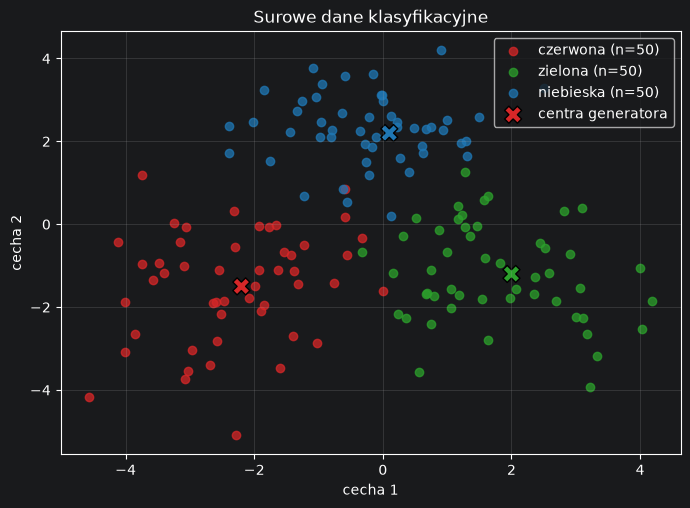

In [130]:
classification_colors = {
    "czerwona": "tab:red",
    "zielona": "tab:green",
    "niebieska": "tab:blue",
}

fig, ax = plt.subplots(figsize=(8, 5.5))
for class_name in class_names:
    class_mask = Y_classification == class_name
    ax.scatter(
        X_classification[class_mask, 0],
        X_classification[class_mask, 1],
        color=classification_colors[class_name],
        alpha=0.75,
        label=f"{class_name} (n={class_mask.sum()})",
    )

ax.scatter(
    class_centers[:, 0],
    class_centers[:, 1],
    color=[classification_colors[name] for name in class_names],
    edgecolor="black",
    marker="X",
    s=150,
    label="centra generatora",
)
ax.set(title="Surowe dane klasyfikacyjne", xlabel="cecha 1", ylabel="cecha 2")
ax.grid(alpha=0.25)
ax.legend()
plt.show()

## 1. Podział danych

Splitter nie kopiuje ani nie transformuje danych - wyznacza indeksy próbek należących do części treningowej i walidacyjnej. `StratifiedKFoldSplitter` tworzy trzy foldy i rozdziela próbki każdej klasy możliwie równomiernie. Do ręcznego przejścia przez dalsze etapy wybieramy pierwszy fold.

In [131]:
manual_splitter = StratifiedKFoldSplitter(
    n_folds=3,
    shuffle=True,
    rng=np.random.default_rng(102),
)
classification_splits = list(
    manual_splitter.split(X_classification, Y_classification)
)

# Każda para zawiera indeksy train i validation jednego foldu.
for split_number, (train_indices, validation_indices) in enumerate(
    classification_splits,
    start=1,
):
    train_counts = np.unique(Y_classification[train_indices], return_counts=True)[1]
    validation_counts = np.unique(
        Y_classification[validation_indices],
        return_counts=True,
    )[1]
    print(
        f"fold {split_number}: train={len(train_indices)}, "
        f"validation={len(validation_indices)}, "
        f"klasy train={train_counts}, klasy validation={validation_counts}"
    )

first_train_indices, first_validation_indices = classification_splits[0]

fold 1: train=99, validation=51, klasy train=[33 33 33], klasy validation=[17 17 17]
fold 2: train=99, validation=51, klasy train=[33 33 33], klasy validation=[17 17 17]
fold 3: train=102, validation=48, klasy train=[34 34 34], klasy validation=[16 16 16]


### Pierwszy fold

Kółka przedstawiają próbki treningowe, a gwiazdki próbki walidacyjne. Kolory nadal oznaczają klasy. Dzięki stratyfikacji każdy zbiór zawiera reprezentantów wszystkich trzech klas.

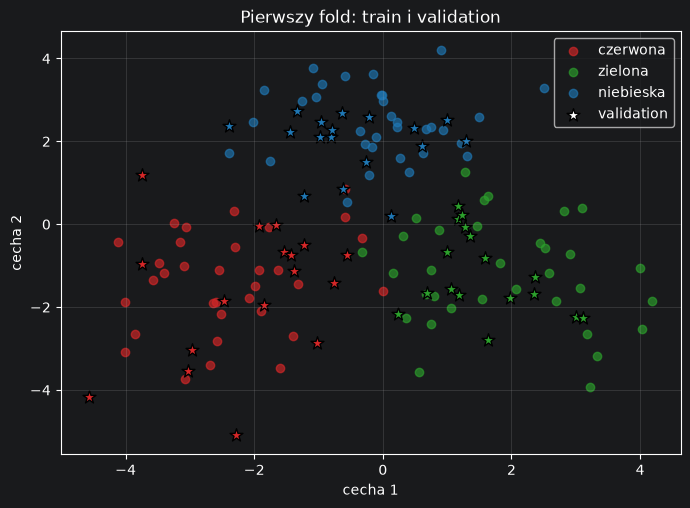

In [132]:
fig, ax = plt.subplots(figsize=(8, 5.5))
for class_name in class_names:
    train_mask = Y_classification[first_train_indices] == class_name
    validation_mask = Y_classification[first_validation_indices] == class_name
    ax.scatter(
        X_classification[first_train_indices[train_mask], 0],
        X_classification[first_train_indices[train_mask], 1],
        color=classification_colors[class_name],
        alpha=0.65,
        label=class_name,
    )
    ax.scatter(
        X_classification[first_validation_indices[validation_mask], 0],
        X_classification[first_validation_indices[validation_mask], 1],
        color=classification_colors[class_name],
        edgecolor="black",
        marker="*",
        s=95,
    )

ax.scatter([], [], color="white", edgecolor="black", marker="*", s=95, label="validation")
ax.set(title="Pierwszy fold: train i validation", xlabel="cecha 1", ylabel="cecha 2")
ax.grid(alpha=0.25)
ax.legend()
plt.show()

## 2. Przygotowanie danych

`ColumnSpec` wskazuje kolumnę i sekwencję jej transformacji. W tym przykładzie obie cechy numeryczne są standaryzowane, a tekstowy cel jest zamieniany przez `LabelEncoder` na indeks klasy. `TabularSplitProcessor` dopasowuje transformery **wyłącznie na train**, a później stosuje je do train i validation.

Dla szeregów czasowych analogiczną rolę pełni `TimeSeriesSplitProcessor`. Po transformacji wierszy tworzy on osobne okna train i validation zgodnie z `WindowSpec`, którego parametry `lookback`, `horizon` i `stride` określają długość historii, horyzont prognozy i odstęp między oknami. W klasyfikacji tablicowej okienkowanie nie jest potrzebne.

In [133]:
classification_x_schema = [
    ColumnSpec(index=0, transformers=[StandardScaler()]),
    ColumnSpec(index=1, transformers=[StandardScaler()]),
]
classification_y_schema = [
    ColumnSpec(
        index=0,
        transformers=[LabelEncoder()],
        # Metryki klasyfikacyjne porównują numeryczne indeksy klas.
        score_transformed=True,
    ),
]

classification_processor_factory = create_tabular_split_processor_factory(
    x_schema=classification_x_schema,
    y_schema=classification_y_schema,
)

# Fabryka wiąże procesor z surowymi danymi i indeksami pierwszego foldu.
first_processor = classification_processor_factory(
    X_classification,
    Y_classification,
    first_train_indices,
    first_validation_indices,
)
first_prepared = first_processor.prepare()

print("typ procesora:", type(first_processor).__name__)
print("X_train:", first_prepared.X_train.shape)
print("Y_train:", first_prepared.Y_train.shape)
print("X_validation:", first_prepared.X_validation.shape)
print("Y_validation_for_scoring:", first_prepared.Y_validation_for_scoring.shape)
print("input_size:", first_prepared.input_size)
print("output_size:", first_prepared.output_size)

typ procesora: TabularSplitProcessor
X_train: (99, 2)
Y_train: (99,)
X_validation: (51, 2)
Y_validation_for_scoring: (51,)
input_size: 2
output_size: 3


`PreparedSplit` rozdziela przestrzeń treningu od przestrzeni scoringu. Model otrzymuje `X_train`, `Y_train` i `X_validation` po transformacjach. Metryki korzystają z `Y_train_for_scoring` i `Y_validation_for_scoring`, które są zapisane w skali właściwej dla oceny. Obiekt zawiera również `input_size` i `output_size`, więc fabryka modelu nie musi znać szczegółów transformacji.

## 3. Utworzenie modelu

`model_factory` otrzymuje generator losowy oraz rozmiary z `PreparedSplit`. Za każdym wywołaniem buduje nową, niewytrenowaną instancję `TrainableModel`. Zapobiega to współdzieleniu wag między foldami.

In [134]:
def create_classification_model(rng, input_size, output_size) -> TrainableModel:
    # Trzy klasy wymagają trzech wyjść Softmax.
    network = NeuralNetwork(
        network_structure=[input_size, 12, output_size],
        activation_functions=[ReLU(), Softmax()],
        rng=rng,
    )
    trainer = BackpropagationTrainer(
        loss=SparseCategoricalCrossEntropy(),
        optimizer=Adam(learning_rate=0.01),
        options=BackpropagationOptions(
            batch_size=16,
            stop_criteria=[MaxEpochs(50)],
            shuffle=True,
        ),
        rng=child_rng(rng),
    )
    return NeuralNetworkModel(network, trainer)


first_model = create_classification_model(
    np.random.default_rng(103),
    first_prepared.input_size,
    first_prepared.output_size,
)

print("typ modelu:", type(first_model).__name__)
print("struktura sieci:", first_model.network.network_structure)

typ modelu: NeuralNetworkModel
struktura sieci: [2, 12, 3]


## 4. Trening i predykcja

Model uczy się wyłącznie na przygotowanej części treningowej. Następnie generuje predykcje zarówno dla train, jak i validation. Procesor zamienia je przez `predictions_for_scoring()` do przestrzeni oczekiwanej przez metryki - w tej klasyfikacji pozostają one macierzą prawdopodobieństw trzech klas.

In [135]:
first_training_result = first_model.train(
    first_prepared.X_train,
    first_prepared.Y_train,
)

# predict() zwraca po jednym rozkładzie prawdopodobieństwa na próbkę.
first_training_predictions_raw = first_model.predict(first_prepared.X_train)
first_validation_predictions_raw = first_model.predict(first_prepared.X_validation)

first_training_predictions = first_processor.predictions_for_scoring(
    first_training_predictions_raw
)
first_validation_predictions = first_processor.predictions_for_scoring(
    first_validation_predictions_raw
)

print("wynik treningu:", first_training_result)
print("predykcje train:", first_training_predictions.shape)
print("predykcje validation:", first_validation_predictions.shape)
print(
    "sumy prawdopodobieństw pierwszych próbek:",
    first_validation_predictions[:3].sum(axis=1),
)

wynik treningu: BackpropagationResult(final_loss=0.07589740306138992, epochs_completed=50, elapsed_seconds=0.20950599998468533)
predykcje train: (99, 3)
predykcje validation: (51, 3)
sumy prawdopodobieństw pierwszych próbek: [1. 1. 1.]


### Jak model rozwiązał problem?

Wytrenowany model z pierwszego foldu wykorzystujemy do sklasyfikowania gęstej siatki punktów w oryginalnej przestrzeni cech. Kolor tła pokazuje przewidywaną klasę, czarne linie granice decyzyjne, kółka próbki treningowe, a gwiazdki próbki walidacyjne.

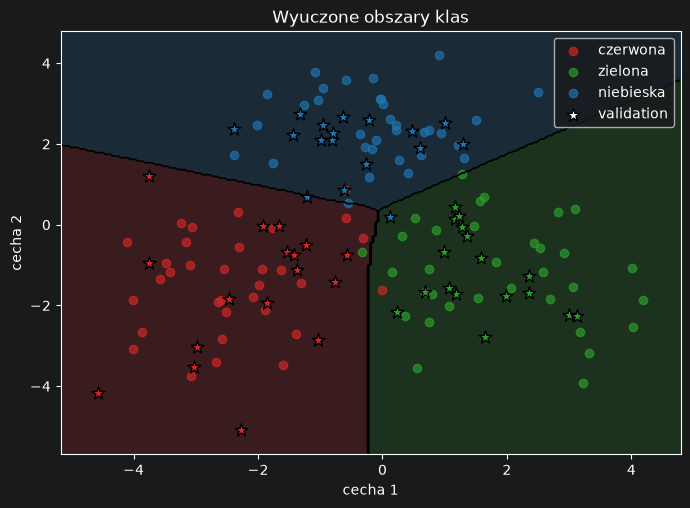

In [136]:
grid_x, grid_y = np.meshgrid(
    np.linspace(X_classification[:, 0].min() - 0.6, X_classification[:, 0].max() + 0.6, 250),
    np.linspace(X_classification[:, 1].min() - 0.6, X_classification[:, 1].max() + 0.6, 250),
)
grid_points = np.column_stack([grid_x.ravel(), grid_y.ravel()])

# Siatka musi przejść przez scaler dopasowany na train pierwszego foldu.
grid_features = first_processor.x_transformer.transform(grid_points)
grid_classes = np.argmax(first_model.predict(grid_features), axis=1)
grid_classes = grid_classes.reshape(grid_x.shape)

# Kolejność kolorów musi odpowiadać indeksom ustalonym przez LabelEncoder.
label_encoder = first_processor.y_transformer.schema[0].transformers[0]
decision_colors = [classification_colors[name] for name in label_encoder.categories]
decision_cmap = ListedColormap(decision_colors)

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.contourf(
    grid_x,
    grid_y,
    grid_classes,
    levels=np.arange(len(label_encoder.categories) + 1) - 0.5,
    cmap=decision_cmap,
    alpha=0.18,
)
ax.contour(
    grid_x,
    grid_y,
    grid_classes,
    levels=np.arange(len(label_encoder.categories) - 1) + 0.5,
    colors="black",
    linewidths=1.2,
)

for class_name in class_names:
    train_mask = Y_classification[first_train_indices] == class_name
    validation_mask = Y_classification[first_validation_indices] == class_name
    ax.scatter(
        X_classification[first_train_indices[train_mask], 0],
        X_classification[first_train_indices[train_mask], 1],
        color=classification_colors[class_name],
        alpha=0.65,
        label=class_name,
    )
    ax.scatter(
        X_classification[first_validation_indices[validation_mask], 0],
        X_classification[first_validation_indices[validation_mask], 1],
        color=classification_colors[class_name],
        edgecolor="black",
        marker="*",
        s=95,
    )

ax.scatter([], [], color="white", edgecolor="black", marker="*", s=95, label="validation")
ax.set(title="Wyuczone obszary klas", xlabel="cecha 1", ylabel="cecha 2")
ax.legend()
plt.show()

## 5. Ocena

Metryki porównują oczekiwane wartości `Y_*_for_scoring` z predykcjami przygotowanymi przez `predictions_for_scoring()`. Najpierw obliczamy wyniki ręcznie dla pierwszego foldu. `Accuracy` powinno być maksymalizowane, natomiast cross-entropy minimalizowane.

In [137]:
classification_metrics = [Accuracy(), CrossEntropyMetric()]

first_training_scores = {
    metric.name: metric.compute(
        first_prepared.Y_train_for_scoring,
        first_training_predictions,
    )
    for metric in classification_metrics
}
first_validation_scores = {
    metric.name: metric.compute(
        first_prepared.Y_validation_for_scoring,
        first_validation_predictions,
    )
    for metric in classification_metrics
}

print("pierwszy fold — train:", first_training_scores)
print("pierwszy fold — validation:", first_validation_scores)

pierwszy fold — train: {'accuracy': 0.9595959595959596, 'cross_entropy': 0.07589740306138992}
pierwszy fold — validation: {'accuracy': 0.9607843137254902, 'cross_entropy': 0.07364778965711594}


## Automatyzacja całego flow przez `ResamplingEvaluator`

Powyżej wykonaliśmy wszystkie etapy jawnie dla jednego foldu. Teraz `ResamplingEvaluator` otrzymuje splitter, fabrykę procesora, fabrykę modelu i metryki. Dla każdego foldu sam powtarza kroki 1–5, zawsze tworząc nowy procesor i nowy model. Używamy świeżego splittera z tym samym ziarnem, aby pełna ewaluacja obejmowała te same trzy podziały.

In [138]:
classification_evaluator = ResamplingEvaluator(
    splitter=StratifiedKFoldSplitter(
        n_folds=3,
        shuffle=True,
        rng=np.random.default_rng(102),
    ),
    model_factory=create_classification_model,
    split_processor_factory=classification_processor_factory,
    metrics=classification_metrics,
    rng=np.random.default_rng(104),
)

# Observer zapisuje metryki train i validation po każdej epoce każdego foldu.
classification_history = EvaluationHistoryObserver()
classification_evaluator.add_observer(classification_history)
classification_evaluator.add_observer(EvaluationConsoleObserver())

classification_result = classification_evaluator.evaluate(
    X_classification,
    Y_classification,
)

Stratified fold 1, epoka 1: loss=1.0364, train={'accuracy': 0.45454545454545453, 'cross_entropy': 1.0363858938217163}, validation={'accuracy': 0.4117647058823529, 'cross_entropy': 1.0751800537109375}
Stratified fold 1, epoka 10: loss=0.1377, train={'accuracy': 0.9696969696969697, 'cross_entropy': 0.13765235245227814}, validation={'accuracy': 0.9803921568627451, 'cross_entropy': 0.1455109566450119}
Stratified fold 1, epoka 20: loss=0.0933, train={'accuracy': 0.9595959595959596, 'cross_entropy': 0.09330622106790543}, validation={'accuracy': 0.9607843137254902, 'cross_entropy': 0.10743096470832825}
Stratified fold 1, epoka 30: loss=0.0780, train={'accuracy': 0.9696969696969697, 'cross_entropy': 0.07801344990730286}, validation={'accuracy': 0.9607843137254902, 'cross_entropy': 0.08351851254701614}
Stratified fold 1, epoka 40: loss=0.0717, train={'accuracy': 0.9595959595959596, 'cross_entropy': 0.07168685644865036}, validation={'accuracy': 0.9607843137254902, 'cross_entropy': 0.082039862871

### `EvaluationResult`

Wynik końcowy zawiera osobny `SplitResult` dla każdego foldu. Możemy odczytać tablice wyników treningowych i walidacyjnych, a także ich średnie oraz odchylenia standardowe. Jest to ocena całego protokołu: podziału, preprocessingu, tworzenia modelu i treningu.

In [139]:
print("typ wyniku:", type(classification_result).__name__)

typ wyniku: EvaluationResult


In [140]:
for metric_name in ("accuracy", "cross_entropy"):
    print()
    print(metric_name)
    print("  train:", classification_result.training_scores(metric_name))
    print("  validation:", classification_result.scores(metric_name))
    print("  średnia train:", classification_result.mean_training_score(metric_name))
    print("  odchylenie train:", classification_result.std_training_score(metric_name))
    print("  średnia validation:", classification_result.mean_validation_score(metric_name))
    print("  odchylenie validation:", classification_result.std_validation_score(metric_name))

print()
print("liczba zakończonych foldów:", len(classification_result.splits))
print("observer otrzymał wynik:", classification_history.evaluation is classification_result)


accuracy
  train: [0.95959596 0.96969697 0.99019608]
  validation: [0.96078431 0.98039216 0.91666667]
  średnia train: 0.9731630025747672
  odchylenie train: 0.0127305893060201
  średnia validation: 0.9526143790849674
  odchylenie validation: 0.026649520310947864

cross_entropy
  train: [0.06893428 0.06596962 0.02849176]
  validation: [0.09421294 0.12209506 0.18966492]
  średnia train: 0.05446522248287996
  odchylenie train: 0.018405848359857008
  średnia validation: 0.13532430678606033
  odchylenie validation: 0.04007517492005704

liczba zakończonych foldów: 3
observer otrzymał wynik: True


### Metryki w kolejnych epokach

Observer historii pozwala zobaczyć nie tylko wynik końcowy, lecz także przebieg uczenia. Linie pokazują średnią z foldów, a pasma zmienność między nimi. Różnica między treningiem i walidacją pomaga rozpoznać przeuczenie.

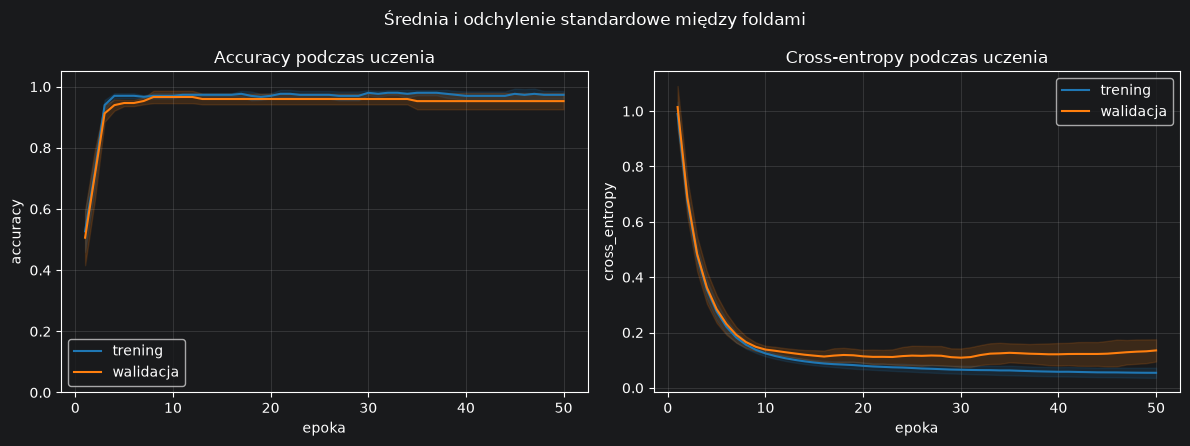

In [141]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
plot_evaluation_history(
    axes[0],
    classification_history,
    "accuracy",
    "Accuracy podczas uczenia",
)
plot_evaluation_history(
    axes[1],
    classification_history,
    "cross_entropy",
    "Cross-entropy podczas uczenia",
)
axes[0].set_ylim(0.0, 1.05)
fig.suptitle("Średnia i odchylenie standardowe między foldami")
fig.tight_layout()
plt.show()

## Podsumowanie

W przykładzie każdy fold przechodzi identyczny, izolowany proces:

1. splitter wyznacza indeksy train i validation,
2. procesor dopasowuje transformacje tylko na train i tworzy `PreparedSplit`,
3. fabryka buduje świeży model na podstawie `input_size` i `output_size`,
4. model jest trenowany i generuje predykcje dla obu części,
5. metryki trafiają do `SplitResult`, a komplet foldów do `EvaluationResult`.

Najważniejszą własnością tego układu jest brak przecieku: dane walidacyjne nie wpływają ani na parametry transformacji, ani na wagi modelu. `ResamplingEvaluator` automatyzuje flow, ale ręczne przejście przez pierwszy fold pokazuje dokładnie, co dzieje się pod spodem.